In [85]:
import csv
from datetime import datetime, timedelta
import random
import pandas as pd

NUM_RECORDS = 500
ANOMALY_RATE = 0.15  # 15% anomaly rate
OUTPUT_FILENAME = "employee_access_dataset.csv"

FIRST_NAMES = [
    "Alice",
    "Liam",
    "Sophia",
    "James",
    "Diana",
    "Olivia",
    "Benjamin",
    "Charlotte",
    "Ian",
    "Lucas",
    "Mia",
    "Noah",
    "Bob",
    "Harper",
    "Charlie",
    "Ethan",
    "Fiona",
    "George",
    "Hannah",
    "Julia",
]
LAST_NAMES = [
    "Smith",
    "Davis",
    "Taylor",
    "Wilson",
    "Prince",
    "Martinez",
    "Moore",
    "Anderson",
    "Malcolm",
    "Thomas",
    "Jackson",
    "White",
    "Jones",
    "Harris",
    "Brown",
    "Hunt",
    "Gallagher",
    "Castanza",
    "Abbott",
    "Roberts",
]

# Generate a pool of 50 unique workers
workers = []
used_ids = set()
for _ in range(50):
  while True:
    worker_id = random.randint(10000, 99999)
    if worker_id not in used_ids:
      used_ids.add(worker_id)
      break
  name = f"{random.choice(FIRST_NAMES)} {random.choice(LAST_NAMES)}"
  workers.append((str(worker_id), name))

num_anomalies = int(NUM_RECORDS * ANOMALY_RATE)
num_benign = NUM_RECORDS - num_anomalies

# Diversity split: ~85% during closed hours, ~15% during normal hours
num_closed_anomalies = int(num_anomalies * 0.85)
num_day_anomalies = num_anomalies - num_closed_anomalies

records = []
start_date = datetime(2026, 11, 1, 0, 0, 0)

# 1. Generate Benign Records (Standard working hours: 08:00 - 18:00)
for _ in range(num_benign):
  worker = random.choice(workers)
  day_offset = random.randint(0, 2)
  hour_offset = random.randint(8, 17)
  timestamp = start_date + timedelta(
      days=day_offset,
      hours=hour_offset,
      minutes=random.randint(0, 59),
      seconds=random.randint(0, 59),
  )
  records.append({
      "Worker ID": worker[0],
      "Name": worker[1],
      "Timestamp": timestamp.strftime("%Y-%m-%d %H:%M:%S"),
      "Anomaly": "No",
  })

# 2. Closed-Hour Anomalies (20:00 - 06:00)
closed_hours = [20, 21, 22, 23, 0, 1, 2, 3, 4, 5]
for _ in range(num_closed_anomalies):
  worker = random.choice(workers)
  day_offset = random.randint(0, 2)
  hour_offset = random.choice(closed_hours)
  actual_day_offset = day_offset + 1 if hour_offset < 6 else day_offset

  timestamp = start_date + timedelta(
      days=actual_day_offset,
      hours=hour_offset,
      minutes=random.randint(0, 59),
      seconds=random.randint(0, 59),
  )
  records.append({
      "Worker ID": worker[0],
      "Name": worker[1],
      "Timestamp": timestamp.strftime("%Y-%m-%d %H:%M:%S"),
      "Anomaly": "Yes",
  })

# 3. Sneaky Daytime Anomalies (08:00 - 18:00)
for _ in range(num_day_anomalies):
  worker = random.choice(workers)
  day_offset = random.randint(0, 2)
  hour_offset = random.randint(8, 17)

  timestamp = start_date + timedelta(
      days=day_offset,
      hours=hour_offset,
      minutes=random.randint(0, 59),
      seconds=random.randint(0, 59),
  )
  records.append({
      "Worker ID": worker[0],
      "Name": worker[1],
      "Timestamp": timestamp.strftime("%Y-%m-%d %H:%M:%S"),
      "Anomaly": "Yes",
  })

random.shuffle(records)

with open(OUTPUT_FILENAME, mode="w", newline="", encoding="utf-8") as file:
  writer = csv.DictWriter(
      file, fieldnames=["Worker ID", "Name", "Timestamp", "Anomaly"]
  )
  writer.writeheader()
  writer.writerows(records)

# Display a preview of the generated records
df_preview = pd.DataFrame(records)
print(df_preview.head(15).to_string(index=False))

Worker ID              Name           Timestamp Anomaly
    98095 Charlotte Malcolm 2026-11-01 23:19:01     Yes
    88792       Julia Brown 2026-11-02 15:30:24      No
    16983      James Harris 2026-11-02 11:07:18      No
    85602     Harper Thomas 2026-11-03 09:02:36      No
    43254    Harper Malcolm 2026-11-02 14:34:53      No
    16983      James Harris 2026-11-03 09:06:52      No
    95186     Ian Gallagher 2026-11-03 15:47:57      No
    52027    Liam Gallagher 2026-11-04 02:40:59     Yes
    72412      Alice Prince 2026-11-01 09:22:36      No
    36448  Charlie Martinez 2026-11-01 16:09:17      No
    95186     Ian Gallagher 2026-11-02 09:25:49      No
    94530    Alice Castanza 2026-11-01 13:41:09      No
    53879      Mia Martinez 2026-11-04 02:05:14     Yes
    85602     Harper Thomas 2026-11-03 08:48:09      No
    17969    Charlie Thomas 2026-11-03 08:21:13      No


CLASSIFICATION PERFORMANCE METRICS TABLE:
              precision  recall  f1-score  support
Normal            0.971   0.859     0.911  425.000
Anomaly           0.516   0.853     0.643   75.000
accuracy          0.858   0.858     0.858    0.858
macro avg         0.743   0.856     0.777  500.000
weighted avg      0.903   0.858     0.871  500.000


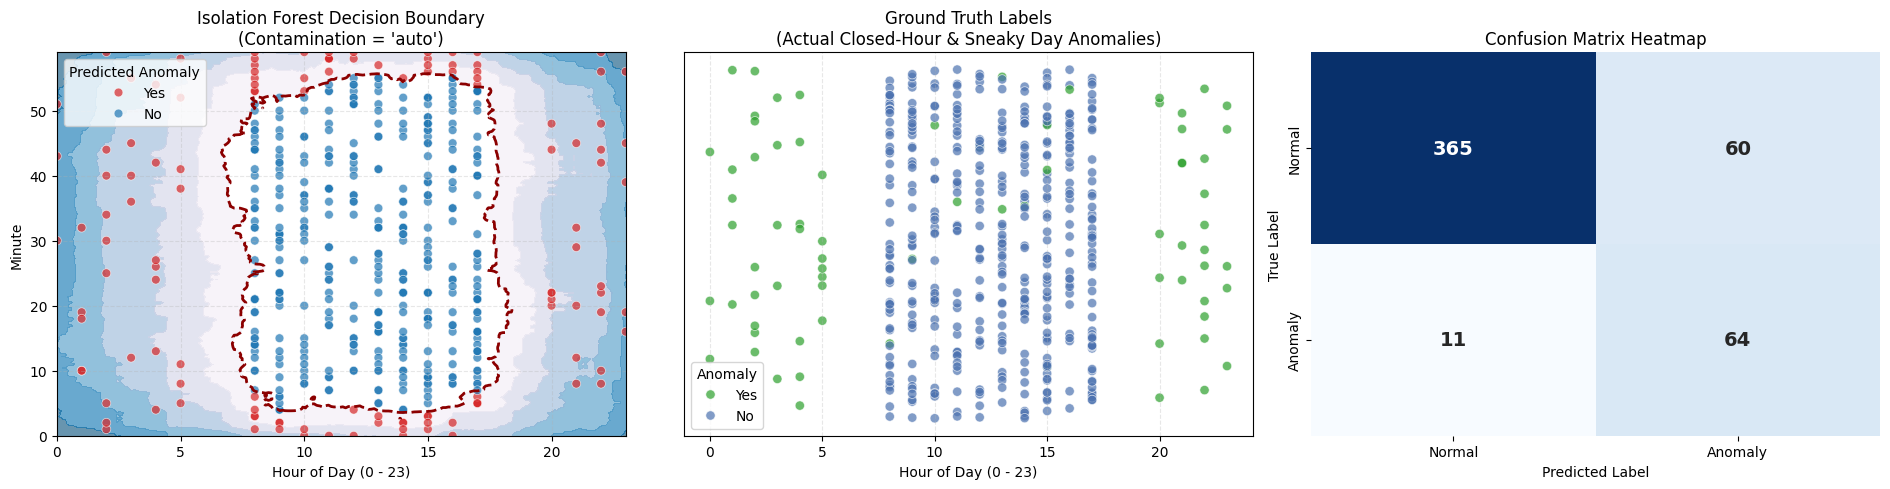

In [86]:
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load data
df = pd.read_csv("employee_access_dataset.csv")

# 2. Feature Engineering & Jitter for clearer visualization
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df["hour"] = df["Timestamp"].dt.hour
df["minute"] = df["Timestamp"].dt.minute
df["jitter"] = [random.uniform(-0.4, 0.4) for _ in range(len(df))]

# 3. Train Isolation Forest Model with contamination='auto' (Realistic unsupervised mode)
X = df[["hour", "minute"]].values
model = IsolationForest(contamination="auto", random_state=42)
df["model_score"] = model.fit_predict(X)
df["Predicted Anomaly"] = df["model_score"].apply(
    lambda x: "Yes" if x == -1 else "No"
)

# 4. Generate Classification Report as a Clean Table
report_dict = classification_report(
    df["Anomaly"],
    df["Predicted Anomaly"],
    target_names=["Normal", "Anomaly"],
    output_dict=True,
)
metrics_df = pd.DataFrame(report_dict).transpose()

print("=" * 65)
print("CLASSIFICATION PERFORMANCE METRICS TABLE:")
print("=" * 65)
print(metrics_df.round(3).to_string())
print("=" * 65)

# 5. Advanced Visualizations (3 Panel Dashboard)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# --- Panel 1: Isolation Forest Decision Boundaries ---
xx, yy = np.meshgrid(np.linspace(0, 23, 200), np.linspace(0, 59, 200))
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

axes[0].contourf(
    xx,
    yy,
    Z,
    levels=np.linspace(Z.min(), 0, 7),
    cmap=plt.cm.PuBu_r,
    alpha=0.6,
)
axes[0].contour(
    xx, yy, Z, levels=[0], linewidths=2, colors="darkred", linestyles="--"
)
sns.scatterplot(
    data=df,
    x="hour",
    y="minute",
    hue="Predicted Anomaly",
    palette={"No": "#1f77b4", "Yes": "#d62728"},
    alpha=0.7,
    s=40,
    ax=axes[0],
)
axes[0].set_title(
    "Isolation Forest Decision Boundary\n(Contamination = 'auto')"
)
axes[0].set_xlabel("Hour of Day (0 - 23)")
axes[0].set_ylabel("Minute")
axes[0].grid(True, linestyle="--", alpha=0.3)

# --- Panel 2: Ground Truth Scatter Plot ---
sns.scatterplot(
    data=df,
    x="hour",
    y="jitter",
    hue="Anomaly",
    palette={"No": "#4c72b0", "Yes": "#2ca02c"},
    alpha=0.7,
    s=45,
    ax=axes[1],
)
axes[1].set_title(
    "Ground Truth Labels\n(Actual Closed-Hour & Sneaky Day Anomalies)"
)
axes[1].set_xlabel("Hour of Day (0 - 23)")
axes[1].set_ylabel("")
axes[1].set_yticks([])
axes[1].grid(True, linestyle="--", alpha=0.3)

# --- Panel 3: Confusion Matrix Heatmap ---
cm = confusion_matrix(df["Anomaly"], df["Predicted Anomaly"], labels=["No", "Yes"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"],
    annot_kws={"size": 14, "weight": "bold"},
    ax=axes[2],
)
axes[2].set_title("Confusion Matrix Heatmap")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.show()